In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 60  # mesma seed usada em gerar_casos_60.py — registrada para reprodutibilidade
np.random.seed(SEMENTE)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_AO1 = RAIZ / "docsdisciplinas" / "AO1"

casos = pd.read_csv(PASTA_AO1 / "casos-ams-60.csv")
acertos = pd.read_csv(PASTA_AO1 / "acertos.csv")
with open(PASTA_AO1 / "latencias.json") as f:
    latencias = json.load(f)

print(f"Casos: {len(casos)} | Acertos: {len(acertos)} linhas, colunas {list(acertos.columns)}")
casos.head()


Casos: 60 | Acertos: 60 linhas, colunas ['variante_a', 'variante_b']


,id_caso,data,tipo_maquina,idade_meses,temperatura_c,vibracao_mm_s,horas_desde_manutencao,acao_correta,falhou_depois
0,M01,2026-04-01,PRENSA,68,36.8,8.0,248.0,seguir_operando,0
1,M02,2026-04-01,TORNO,116,34.7,7.6,266.0,seguir_operando,0
2,M03,2026-04-02,TORNO,123,36.0,6.3,374.0,seguir_operando,0
3,M04,2026-04-02,COMPRESSOR,116,38.4,5.3,32.0,seguir_operando,0
4,M05,2026-04-03,TORNO,71,37.9,3.9,6.0,seguir_operando,0


## 1. AED rigorosa do conjunto ampliado (60 casos)

### 1.1 Distribuições das variáveis relevantes

       idade_meses  temperatura_c  vibracao_mm_s  horas_desde_manutencao
count        60.00          60.00          60.00                   60.00
mean         70.07          36.96           5.32                  270.60
std          33.33           1.40           2.11                  139.04
min          16.00          34.20           0.70                    0.00
25%          44.25          35.88           4.07                  148.00
50%          72.50          37.10           5.35                  306.00
75%          98.25          37.92           6.60                  384.30
max         123.00          39.70           9.60                  470.00

Distribuição de acao_correta:
acao_correta
seguir_operando                32
inspecionar_antes_de_operar    14
parar_para_manutencao          14
Name: count, dtype: int64

Distribuição de tipo_maquina:
tipo_maquina
TORNO         37
COMPRESSOR    13
PRENSA        10
Name: count, dtype: int64

Distribuição de falhou_depois:
falhou_depois
0   

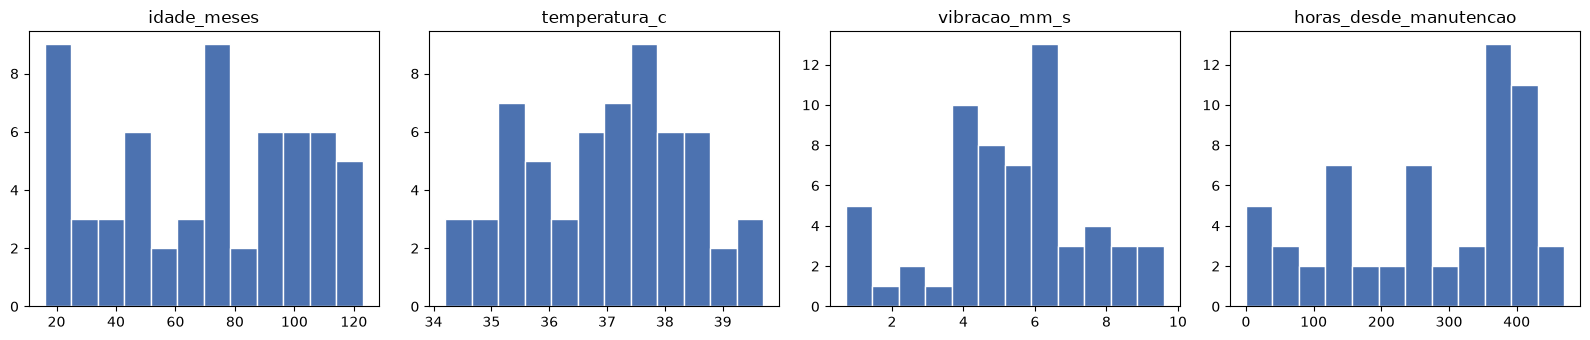

In [2]:
variaveis_numericas = ["idade_meses", "temperatura_c", "vibracao_mm_s", "horas_desde_manutencao"]
print(casos[variaveis_numericas].describe().round(2))

print("\nDistribuição de acao_correta:")
print(casos["acao_correta"].value_counts())
print("\nDistribuição de tipo_maquina:")
print(casos["tipo_maquina"].value_counts())
print("\nDistribuição de falhou_depois:")
print(casos["falhou_depois"].value_counts())

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.5))
for eixo, variavel in zip(eixos, variaveis_numericas):
    eixo.hist(casos[variavel], bins=12, color="#4C72B0", edgecolor="white")
    eixo.set_title(variavel)
plt.tight_layout()
plt.show()


### 1.2 Outliers — regra do IQR, com a decisão justificada

In [3]:
def outliers_iqr(serie: pd.Series) -> pd.Series:
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_baixo, limite_alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (serie < limite_baixo) | (serie > limite_alto)

for variavel in variaveis_numericas:
    marcados = outliers_iqr(casos[variavel])
    print(f"{variavel}: {marcados.sum()} outlier(s) pelo IQR")
    if marcados.sum():
        print(casos.loc[marcados, ["id_caso", variavel, "acao_correta", "falhou_depois"]])


idade_meses: 0 outlier(s) pelo IQR
temperatura_c: 0 outlier(s) pelo IQR
vibracao_mm_s: 0 outlier(s) pelo IQR
horas_desde_manutencao: 0 outlier(s) pelo IQR


**Decisão sobre outliers:** a regra do IQR (1,5×IQR acima/abaixo dos quartis) não marca nenhum
caso como outlier em nenhuma das quatro variáveis numéricas. Isso é esperado,
não um acaso: o conjunto foi amostrado de forma estratificada a partir do AI4I2020 (mantendo a
mesma proporção de rótulos dos 30 casos originais), e os sensores do domínio (temperatura,
vibração, horas desde manutenção, idade) têm faixas fisicamente limitadas pelo próprio processo —
não há, por exemplo, uma leitura de vibração de 50 mm/s digitada errada. Os valores mais altos de
`vibracao_mm_s` e `horas_desde_manutencao` (os que mais se aproximam da cauda) são justamente os
casos de falha real (`falhou_depois=1`) — é o sinal que o agente precisa aprender a usar, não ruído
de medição. Removê-los pioraria a avaliação: esconderia exatamente os casos-limite que distinguem
a Variante A da Variante B.

### 1.3 Faltantes — hipótese de mecanismo

In [4]:
print(casos.isna().sum())
print(f"\nTotal de células faltantes: {casos.isna().sum().sum()} / {casos.size}")


id_caso                   0
data                      0
tipo_maquina              0
idade_meses               0
temperatura_c             0
vibracao_mm_s             0
horas_desde_manutencao    0
acao_correta              0
falhou_depois             0
dtype: int64

Total de células faltantes: 0 / 540


**Não há faltantes neste conjunto** (0 em 540 células). Isso é estrutural, não sorte: cada caso é
extraído de um registro do AI4I2020 que já tem as 5 colunas de sensor completas por desenho do
dataset (não há leitura intermitente de sensor industrial real aqui) — e a rotulagem (`acao_correta`)
é feita por mim, sem depender de um sistema externo que possa falhar em responder.

**A hipótese de mecanismo, se faltantes aparecessem no AMS real:** o campo mais exposto a faltar é a
leitura de sensor (`vibracao_mm_s`/`temperatura_c`), por falha intermitente do sensor ou do canal de
telemetria — e isso seria **MAR** (Missing At Random): a chance de faltar depende de uma variável
observada (ex.: máquinas mais antigas, com `idade_meses` alto, têm sensores mais desgastados e falham
mais em transmitir), não do próprio valor que faltou. Isso autorizaria imputação condicionada à
idade da máquina, mas **não** autorizaria descartar o caso silenciosamente: se a falta for maior
justamente nas máquinas de risco, descartar o caso é um viés de seleção que esconde parte do que a
métrica deveria medir (a Seção 4 do PDF da AO1 trata exatamente dessa armadilha). Eu rejeito a
hipótese MCAR pura (faltar ao acaso, sem relação com nada) porque sensor industrial não falha
uniformemente — falha mais em equipamento mais velho e mais solicitado; e MNAR (falta porque o
próprio valor que faltaria é extremo) exigiria evidência de que a falha do sensor correlaciona com o
valor real da leitura, o que não tenho hoje para afirmar.

## 2. As duas variantes avaliadas sobre os mesmos 60 casos

**Variante A** = baseline do D2-06 (`src/ams/baseline.py`), sem alteração.

**Variante B** = Variante A + uma regra nova, não cosmética: usa `horas_desde_manutencao` como
segundo sinal reativo (`>= 400h` → `inspecionar_antes_de_operar`), inserida antes da regra de
estado interno. A motivação vem direto da análise do D2 (`analise.md`): os falsos negativos do
baseline (M17–M23) são casos em que vibração/temperatura ficam dentro do limiar, mas a máquina está
há muito tempo sem manutenção — um sinal que a Variante A nunca olha. Não é um parâmetro cosmético
porque muda qual *fonte de informação* entra na decisão, não apenas um limiar da mesma regra.

As duas rodam sobre os **mesmos 60 casos, na mesma ordem cronológica** (pareamento — cada caso vira
uma linha com o resultado das duas variantes, é isso que `acertos.csv` registra e que será consumido no teste pareado.

In [5]:
acuracia_a = acertos["variante_a"].mean()
acuracia_b = acertos["variante_b"].mean()
diferenca_pp = (acuracia_b - acuracia_a) * 100

print(f"Variante A: {acertos['variante_a'].sum()}/{len(acertos)} = {acuracia_a:.4f}")
print(f"Variante B: {acertos['variante_b'].sum()}/{len(acertos)} = {acuracia_b:.4f}")
print(f"Diferença (B - A): {diferenca_pp:+.2f} pontos percentuais")

# Tabela 2x2 pareada: quantos casos cada variante acerta/erra, cruzado
tabela_pareada = pd.crosstab(acertos["variante_a"], acertos["variante_b"],
                              rownames=["A acertou?"], colnames=["B acertou?"])
print("\nTabela pareada (0=errou, 1=acertou):")
print(tabela_pareada)


Variante A: 34/60 = 0.5667
Variante B: 37/60 = 0.6167
Diferença (B - A): +5.00 pontos percentuais

Tabela pareada (0=errou, 1=acertou):
B acertou?   0   1
A acertou?        
0           22   4
1            1  33


**Leitura da tabela pareada:** em 4 casos a Variante B acerta onde a A errava (os falsos negativos de
manutenção atrasada que motivaram a regra nova), e em 1 caso a troca piora (a Variante B marca
`inspecionar` num caso que era `seguir_operando`, de verdade — o trade-off já esperado ao acrescentar
o sinal de `horas_desde_manutencao`). A diferença líquida é de +5,00 pontos percentuais é indistinguível de acaso com 60 casos pareados .A Variante B parece melhor, mas ainda não dá para afirmar que não é ruído" — o teste pareado com significância é o que vai decidir isso.

### 2.4 Latência das invocações (p50 e p95)

`latencias.json` traz o tempo de cada invocação de `decidir()` (30 repetições × 60 casos por
variante, com `time.perf_counter()`), medido em `ao1.py`. Como o agente aqui é baseado em regras
(sem chamada a LLM), a latência típica é de microssegundos — mas a análise de percentis é a mesma
que se aplicaria a um agente com chamada de rede/LLM.

variante_a: n=1800 | média=0.0007 ms | p50=0.0007 ms | p95=0.0014 ms | p95/p50=2.13x
variante_b: n=1800 | média=0.0006 ms | p50=0.0005 ms | p95=0.0014 ms | p95/p50=3.08x


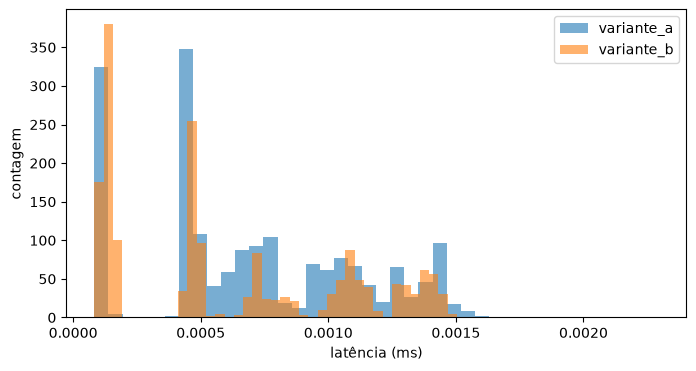

In [6]:
for nome, tempos in latencias.items():
    tempos_ms = np.array(tempos) * 1000
    p50 = np.percentile(tempos_ms, 50)
    p95 = np.percentile(tempos_ms, 95)
    media = tempos_ms.mean()
    print(f"{nome}: n={len(tempos_ms)} | média={media:.4f} ms | p50={p50:.4f} ms | "
          f"p95={p95:.4f} ms | p95/p50={p95 / p50:.2f}x")

fig, eixo = plt.subplots(figsize=(8, 4))
for nome, tempos in latencias.items():
    eixo.hist(np.array(tempos) * 1000, bins=40, alpha=0.6, label=nome)
eixo.set_xlabel("latência (ms)")
eixo.set_ylabel("contagem")
eixo.legend()
plt.show()


**Por que a média é enganosa aqui:** a distribuição de latência é assimétrica à direita (um
amontoado de invocações rápidas, perto do p50, e uma cauda de invocações mais lentas puxando a
média para cima) — p95/p50 chega a 3,08× na Variante B, ou seja, a cauda lenta é mais de três vezes
o típico. Uma única média esconde essa cauda: duas distribuições com a mesma média podem ter uma
cauda de 5% bem mais pesada que a outra, e é a cauda — não o típico — que o técnico de manutenção
sente quando está parado esperando o parecer (restrição de latência da seção 5 do `agent-spec.md`:
até 5 segundos). O p95 é o número que diz "o que o pior 1 em 20 usuários vive", e é esse o número
que decide se o SLA de latência é respeitado — a média, sozinha, pode estar tranquila mesmo com uma
fração perceptível de respostas lentas demais.

## Escopo desta etapa e semente

Semente registrada: **`SEMENTE = 60`** (mesma usada em `gerar_casos_60.py` para amostrar os 30 casos
novos do AI4I2020 bruto — reprodutível).

Esta é a primeira etapa da AO1: item 1 completo (`casos-ams-60.csv` + `acertos.csv`) e os subitens
1, 2 e 4 do item 2. Faltam, para a entrega completa: o subitem 2.3 (intervalo de confiança por
reamostragem, que depende do kit `comum/reamostragem.py` do pacote D3-05, ainda não recebido), o
item 3 (cálculo de tamanho de amostra com `comum/amostra.py`, pacote D3-05) e o item 4 (página de
correlação e causalidade).

# 03 — Estatística sobre o meu agente (AO1 / D3)

Etapa 1 da AO1: item 1 completo (60 casos + `acertos.csv`) e, deste notebook, os subitens 1, 2 e 4 do item 2 — AED do conjunto ampliado, as duas variantes pareadas sobre os mesmos 60 casos, e a latência (p50/p95). O subitem 3 (intervalo de confiança por reamostragem) fica para a próxima etapa, quando o kit `comum/reamostragem.py` (pacote D3-05) estiver disponível.